# Data analysis
- Imports homeostatic data from '260309_FUSED_Lgr6CreERfromD3_homeo_Raw.csv'
- Produces csv files used for analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
import clones


plt.rcParams['figure.figsize'] = (4, 3)


def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)

def laggedevent(movebytimeclone, dBas1, dSup1, dBas2, dSup2):
    ntimes  = np.shape(movebytimeclone)[1]
    nclones = np.shape(movebytimeclone)[0]
    
    event = np.zeros((ntimes - 2, ntimes - 1), dtype = 'int32')

    for t in range(ntimes - 1):
        for c in range(nclones):
            for n in range(1,ntimes - 1):
                if t + n < ntimes:
                    event[n-1, t] += (movebytimeclone[c, t, dBas1, dSup1] == 1) and (movebytimeclone[c, t+n, dBas2, dSup2] == 1)
    return event

def evenbias(clonesize, singletime = False):
    #Mathematica:  p = 1/m; Simplify[Sum[p*(1 - p)^(2*k - 1), {k, 1, Infinity}]]
    #We need a way of assessing the error on even bias
    
    if singletime == True:
        clonesize = np.array(clonesize[np.array(clonesize) > 0])
        fracEven = 1 - np.mean(clonesize % 2) 
        avSize    = np.mean(clonesize)
        fracexpect  = (avSize - 1)/(2*avSize - 1)
        
        return (fracEven - fracexpect)/(1 - fracexpect)
    else:
        clonesize = [np.array(cst[np.array(cst) > 0]) for cst in clonesize]
        avSize = np.array([np.mean(cst) for cst in clonesize])
        fracEven = np.array([1 - np.mean(cst % 2) for cst in clonesize])
        
    fracexpect  = (avSize - 1)/(2*(avSize) - 1)
    return (fracEven - fracexpect)/(1 - fracexpect)


'''  
    Compute the counts tensor for experiments
'''

def extend_livesize(livesize):
    nclones = np.shape(livesize)[0]
    time0 = np.zeros((nclones, 1, 2), dtype = 'int32')
    time0[:,0,0] = 1
    return np.concatenate((time0, livesize), axis = 1)



def get_allmoves(livesize, full_timelapse, use_df = False):
    ''' 
        Define allmoves in the following way:
        allmoves[time, bas_t-1, sup_t-1, bast, bast, dSup2, mouse, clone type]
        
        We only specify moves starting from surviving clone numbers
        
        This is convenient for specifying likelihood
        
        Then we specify the unique transitions which occur in the data
    '''
    
    full_livesize = extend_livesize(livesize)

    
    full_timelapse['max_tot'] = np.max(np.sum(full_livesize,2),1)
    
    full_timelapse['ctype'] = ''
    full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
    full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
    full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'
    
    mice = full_timelapse['mice_ID'].unique()
    max_bas = full_livesize[:,:,0].max() + 1
    max_sup = full_livesize[:,:,1].max() + 1
    
    ntimes = np.shape(full_livesize)[1] - 1
    
    ctypes = ['S', 'T', 'D']
    ntypes  = len(ctypes)
   
    allmoves = np.zeros((ntimes, max_bas, max_sup, max_bas, max_sup, ntypes, len(mice)), dtype = 'int32')

    for m in range(len(mice)):
        for cT in range(len(ctypes)):
            cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[cT]))[0]
            for c in range(len(cids)):
                for t in range(ntimes):
                    bas0 = full_livesize[cids[c],t,0]
                    sup0 = full_livesize[cids[c],t,1]
                    bas1 = full_livesize[cids[c],t+1,0]
                    sup1 = full_livesize[cids[c],t+1,1]
                    if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:
                        allmoves[t, bas0, sup0, bas1, sup1, cT, m] += 1
            
    allmoves_bas = np.sum(allmoves, axis = (2,4))
             
    if use_df:
        all_moves     = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'supra0', 'basal1', 'supra1', 'count'])
        all_moves_bas = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'basal1', 'count'])

        for m in range(len(mice)):
            for cT in range(len(ctypes)):
                cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[cT]))[0]
                for t in range(ntimes):
                    unqclones = np.unique(full_livesize[cids,t:t+2,:], axis = 0)
                    for u in unqclones:
                        bas0 = u[0,0]
                        sup0 = u[0,1]
                        bas1 = u[1,0]
                        sup1 = u[1,1]
                        if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[cT], 'basal0': bas0, 'supra0': sup0, 'basal1': bas1, 'supra1': sup1, 'count': allmoves[t, bas0, sup0, bas1, sup1, cT, m]}
                            all_moves = pd.concat([all_moves, pd.DataFrame([to_append])], ignore_index=True)  
                            
                    unqbas = np.unique(full_livesize[cids,t:t+2,0], axis = 0)
                    for u in unqbas:
                        bas0 = u[0]
                        bas1 = u[1]
                        if bas0 > 0 and bas1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[cT], 'basal0': bas0, 'basal1': bas1, 'count': allmoves_bas[t, bas0, bas1, cT, m]}
                            all_moves_bas = pd.concat([all_moves_bas, pd.DataFrame([to_append])], ignore_index=True)              
        
        return all_moves, all_moves_bas
    else:
        return allmoves, allmoves_bas
        


import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)
    
ct = 'Lgr6'

/tmp/ipykernel_217409/1118733106.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  full_timelapse.fillna(miss_flag, inplace=True)


Repairing basal CS mistakes for [189]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Repairing basal CS mistakes for [189]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Saved to: data_Lgr6.pkl


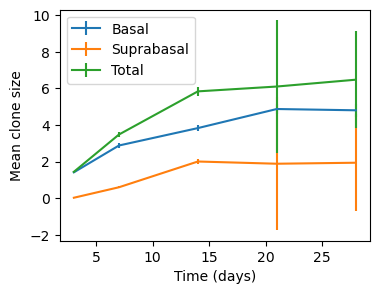

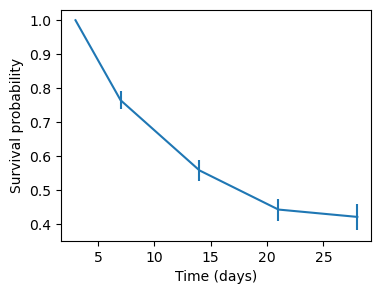

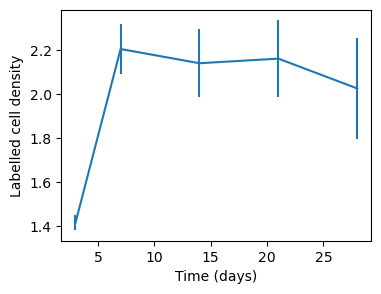

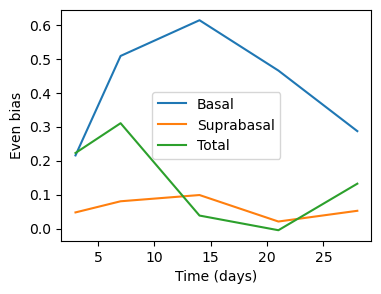

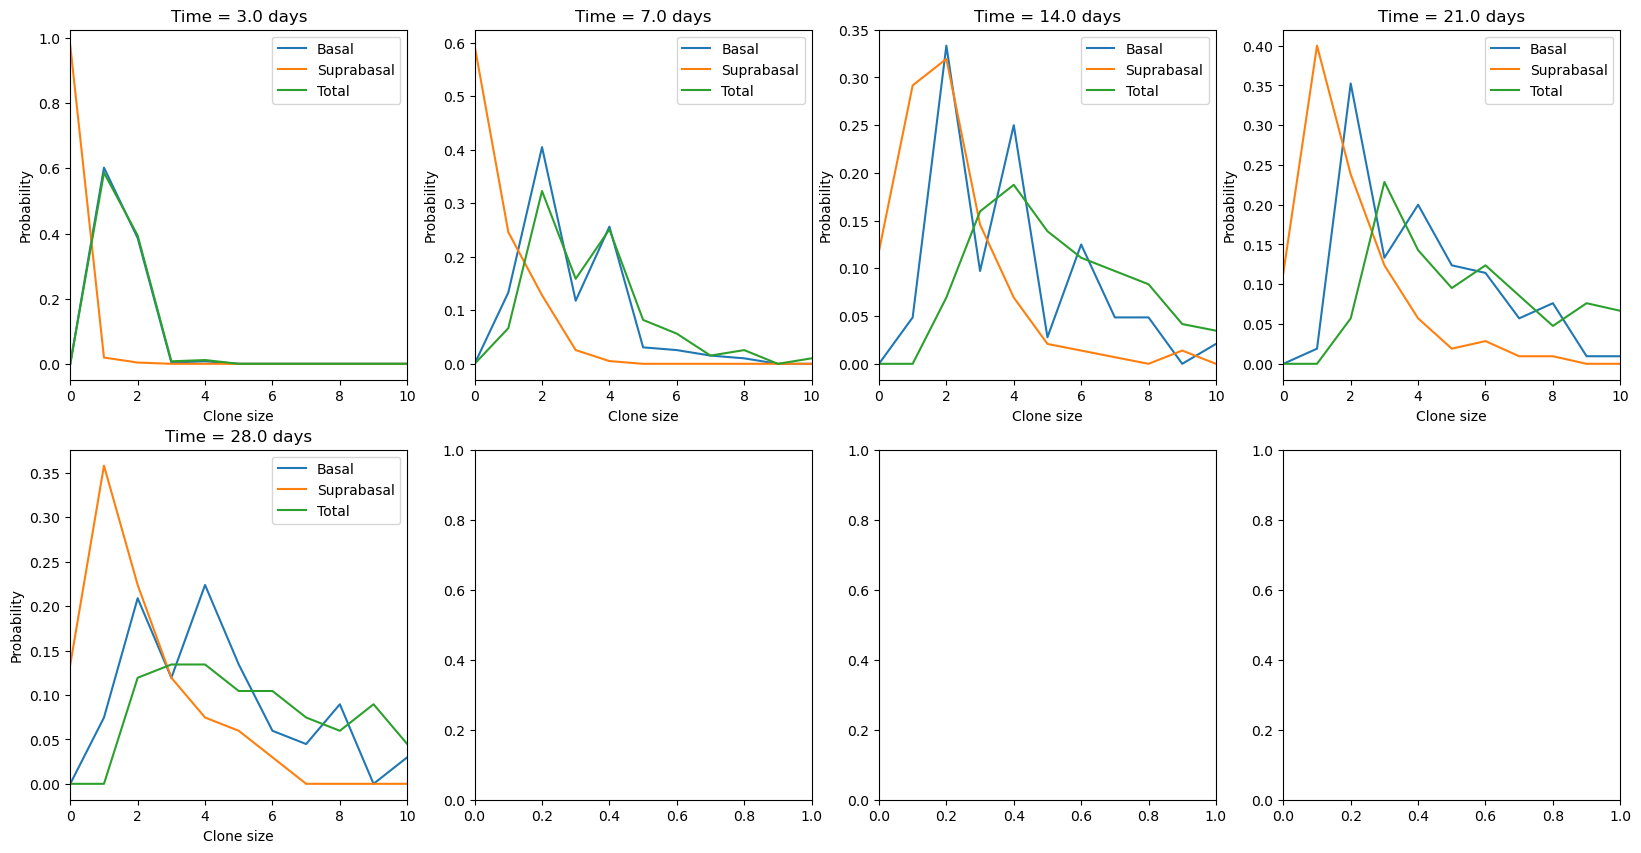

In [2]:
# Control data
filename = './260309_FUSED_Lgr6CreERfromD3_homeo_Raw.csv'

miss_flag = -100

alldata = pd.read_csv(filename, sep=';')
alldata['sex'] = [m[0] for m in alldata['mice_ID'].values]
mice = list(alldata['mice_ID'].unique())
times = list(sorted(alldata['temps'].unique()))
bas_names = ['D' + str(t) + '.basal' for t in times]
sup_names = ['D' + str(t) + '.supra' for t in times]
time_names = bas_names + sup_names
allclones = alldata['clone'].unique()

#Time-course data
full_timelapse = pd.DataFrame(columns = ['sex', 'mice_ID', 'clone'] + time_names)

for c in allclones:
    clone_data = alldata.query('clone ==' + str(c)).copy()
    assert(len(clone_data['mice_ID'].unique()) == 1)
    
    clone_data.fillna(miss_flag, inplace=True)
    bas_data = {'D' + str(clone_data.temps.values[i]) + '.basal': int(clone_data.basal.values[i]) for i in range(len(clone_data))}
    sup_data = {'D' + str(clone_data.temps.values[i]) + '.supra': int(clone_data.supra.values[i]) for i in range(len(clone_data))}
    to_append = {'sex': clone_data['sex'].values[0], 'mice_ID': clone_data['mice_ID'].values[0], 'clone': c, **bas_data, **sup_data}
    full_timelapse = pd.concat([full_timelapse, pd.DataFrame([to_append])], ignore_index=True)

full_timelapse.fillna(miss_flag, inplace=True)


#Combined data
livesize = np.zeros((len(allclones), len(times), 2), dtype = 'int32')
livesize[:,:,0] = np.array(full_timelapse[bas_names].values, dtype = 'int32')
livesize[:,:,1] = np.array(full_timelapse[sup_names].values, dtype = 'int32')
lcs = clones.lanalysis(livesize, tvals = times, containsBasal = True)


all_moves, all_moves_bas = get_allmoves(livesize, full_timelapse, True)

data = {}
data['ctrBasalsize'] = lcs.av_bas_cs
data['ctrSuprasize'] = lcs.av_sup_cs
data['ctrTotalsize'] = lcs.av_tot_cs
data['ctrBasalEvenbias'] = lcs.ev_bas_cs
data['ctrSupraEvenbias'] = lcs.ev_sup_cs
data['ctrTotalEvenbias'] = lcs.ev_tot_cs

data['livesize'] = livesize
data['ctrjointpdf'] = lcs.joint_pdf

data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

data['all_moves'] = lcs.allmoves()
data['all_moves_bas'] = lcs.allmoves_bas()

data['ct_all_moves'] = all_moves
data['ct_all_moves_bas'] = all_moves_bas


cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

data['ctrpdf'] = cpdf

data['surprob'] = lcs.pers
data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
data['lcd']     = lcs.lcd
data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
data['nallc'] = lcs.non_missing
data['ctrNsamples'] = lcs.nsur

data['ctrTimeClonesize'] = lcs.tvals


ct = 'Lgr6'
save_object(data,    f'data_{ct}.pkl')
print('Saved to: ' + f'data_{ct}.pkl')

plt.figure()
plt.errorbar(lcs.tvals[lcs.av_bas_cs > 0], lcs.av_bas_cs[lcs.av_bas_cs > 0], lcs.se_bas_cs[lcs.av_bas_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_sup_cs > 0], lcs.av_sup_cs[lcs.av_sup_cs > 0], lcs.se_sup_cs[lcs.av_sup_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_tot_cs > 0], lcs.av_tot_cs[lcs.av_tot_cs > 0], lcs.se_tot_cs[lcs.av_tot_cs > 0])    
plt.legend(['Basal', 'Suprabasal', 'Total'])
plt.xlabel('Time (days)')
plt.ylabel('Mean clone size')   
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.pers, np.sqrt(lcs.pers*(1-lcs.pers)/lcs.non_missing))
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.lcd, lcs1.se_bas_cs)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')
plt.show()

plt.figure()
plt.plot(lcs.tvals, lcs.ev_bas_cs, label = 'Basal')
plt.plot(lcs.tvals, lcs.ev_sup_cs, label = 'Suprabasal')
plt.plot(lcs.tvals, lcs.ev_tot_cs, label = 'Total')  
plt.legend()  
plt.xlabel('Time (days)')
plt.ylabel('Even bias')
plt.legend()
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(20, 10))

for t in range(len(lcs.tvals)):
    xx = t // 4
    yy = t % 4
    axs[xx,yy].plot(cpdf[t,:,:].T)
    axs[xx,yy].legend(['Basal', 'Suprabasal', 'Total'])
    axs[xx,yy].set_xlabel('Clone size')
    axs[xx,yy].set_ylabel('Probability')
    axs[xx,yy].set_xlim([0, 10])
    axs[xx,yy].set_title('Time = ' + str(lcs.tvals[t]) + ' days')
plt.show()

In [3]:
full_timelapse['max_tot'] = np.max(np.sum(livesize,2),1)
full_timelapse['ctype'] = ''
full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'

full_timelapse

,sex,mice_ID,clone,D3.basal,D7.basal,D14.basal,D21.basal,D28.basal,D3.supra,D7.supra,D14.supra,D21.supra,D28.supra,max_tot,ctype
0,M,M18_Lgr6Cre_V1,18001,2,2,4,4,-100,0,1,1,1,-100,5,S
1,M,M18_Lgr6Cre_V1,18002,2,2,4,5,-100,0,0,2,4,-100,9,S
2,M,M18_Lgr6Cre_V1,18003,1,2,5,6,-100,0,0,4,5,-100,11,S
3,M,M18_Lgr6Cre_V1,18004,1,4,6,3,-100,0,0,4,3,-100,10,S
4,M,M18_Lgr6Cre_V1,18005,2,0,0,0,-100,0,2,0,0,-100,2,T
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,M,M29_Lgr6Cre_V1,29025,1,1,0,0,0,0,1,0,0,0,2,T
262,M,M29_Lgr6Cre_V1,29026,2,0,0,0,0,0,1,0,0,0,2,T
263,M,M29_Lgr6Cre_V1,29027,1,3,2,0,0,0,0,1,0,0,3,S
264,M,M29_Lgr6Cre_V1,29028,1,3,2,2,3,0,1,2,0,1,4,S


In [4]:
ls = lcs.livesize[:,:,0]

np.sum(ls*(ls > 0),0)/np.sum(ls > 0,0)

array([1.41698842, 2.88205128, 3.83333333, 4.30252101, 4.6       ])

In [5]:
'''  
    Compute the counts tensor for experiments
'''

def extend_livesize(livesize):
    nclones = np.shape(livesize)[0]
    time0 = np.zeros((nclones, 1, 2), dtype = 'int32')
    time0[:,0,0] = 1
    return np.concatenate((time0, livesize), axis = 1)

full_timelapse['max_tot'] = np.max(np.sum(livesize,2),1)
full_timelapse['ctype'] = ''
full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'

full_livesize = extend_livesize(livesize)

ctypes = ['S', 'T', 'D']

ntimes = len(times)
ntypes  = len(ctypes)
nlayers = 2
max_bas = livesize[:,:,0].max() + 1
max_sup = livesize[:,:,1].max() + 1

''' 
    Define allmoves in the following way:
    allmoves[time, bas_t-1, sup_t-1, bast, bast, dSup2, mouse, clone type]
    
    We only specify moves starting from surviving clone numbers
    
    This is convenient for specifying likelihood
    
    Then we specify the unique transitions which occur in the data
'''
allmoves = np.zeros((len(times), max_bas, max_sup, max_bas, max_sup, ntypes, len(mice)), dtype = 'int32')

for m in range(len(mice)):
    for ct in range(len(ctypes)):
        cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
        for c in range(len(cids)):
            for t in range(ntimes):
                bas0 = full_livesize[cids[c],t,0]
                sup0 = full_livesize[cids[c],t,1]
                bas1 = full_livesize[cids[c],t+1,0]
                sup1 = full_livesize[cids[c],t+1,1]
                if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:
                    allmoves[t, bas0, sup0, bas1, sup1, ct, m] += 1
          
allmoves_bas = np.sum(allmoves, axis = (2,4))
                        
all_moves     = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'supra0', 'basal1', 'supra1', 'count'])
all_moves_bas = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'basal1', 'count'])

for m in range(len(mice)):
    for ct in [0]:
        cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
        for t in range(ntimes):
            unqclones = np.unique(full_livesize[cids,t:t+2,:], axis = 0)
            for u in unqclones:
                bas0 = u[0,0]
                sup0 = u[0,1]
                bas1 = u[1,0]
                sup1 = u[1,1]
                if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:                    
                    to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'supra0': sup0, 'basal1': bas1, 'supra1': sup1, 'count': allmoves[t, bas0, sup0, bas1, sup1, ct, m]}
                    all_moves = pd.concat([all_moves, pd.DataFrame([to_append])], ignore_index=True)  
                    
            unqbas = np.unique(full_livesize[cids,t:t+2,0], axis = 0)
            for u in unqbas:
                bas0 = u[0]
                bas1 = u[1]
                if bas0 > 0 and bas1 >= 0:                    
                    to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'basal1': bas1, 'count': allmoves_bas[t, bas0, bas1, ct, m]}
                    all_moves_bas = pd.concat([all_moves_bas, pd.DataFrame([to_append])], ignore_index=True)              


In [6]:
alldata['total'] = alldata['basal'] + alldata['supra']

surdata = alldata.copy()
surdata = surdata[~np.isnan(surdata['total'])]
surdata = surdata[surdata['basal'] > 0]
surdata = surdata.astype({'basal': 'int', 'supra': 'int', 'total': 'int'})

# average, sem, and number of clones for dataframe alldata
summary = surdata.groupby(['sex', 'mice_ID', 'temps']).agg({'basal': ['mean', 'sem', 'count'], 'supra': ['mean', 'sem', 'count'], 'total': ['mean', 'sem', 'count']})
summary

basal                     supra                  \
                               mean       sem count      mean       sem count   
sex mice_ID         temps                                                       
F   F10b_Lgr6Cre_V5 3      1.078947  0.044331    38  0.000000  0.000000    38   
                    7      2.500000  0.201914    26  0.423077  0.148563    26   
                    14     3.736842  0.417750    19  2.105263  0.252412    19   
                    21     4.875000  0.426956    16  2.062500  0.280903    16   
                    28     5.000000  0.447214    16  2.125000  0.385951    16   
    F11b_Lgr6Cre_V5 3      1.517241  0.127699    29  0.034483  0.034483    29   
                    7      2.826087  0.271522    23  0.652174  0.161621    23   
                    14     2.947368  0.448999    19  1.631579  0.174559    19   
                    21     3.437500  0.689013    16  1.312500  0.338117    16   
                    28     3.230769  0.661717    13  1.307692  0.382043    13   
    F13_Lgr6Cre_V4  3      1.348837  0.080720    43  0.000000  0.000000    43   
                    7      3.892857  0.452329    28  1.071429  0.184939    28   
                    14     4.047619  0.527691    21  2.761905  0.462420    21   
                    21     4.642857  0.760329    14  1.500000  0.251370    14   
M   M18_Lgr6Cre_V1  3      1.500000  0.091946    46  0.000000  0.000000    46   
                    7      2.418605  0.188931    43  0.302326  0.085070    43   
                    14     4.172414  0.427125    29  1.896552  0.355619    29   
                    21     4.785714  0.727623    14  2.642857  0.540727    14   
    M29_Lgr6Cre_V1  3      1.448276  0.093984    29  0.034483  0.034483    29   
                    7      3.105263  0.438596    19  1.000000  0.229416    19   
                    14     4.142857  0.678210    14  2.642857  0.464180    14   
                    21     4.272727  1.071031    11  2.818182  0.795649    11   
                    28     5.500000  1.388730     8  2.500000  0.654654     8   
    M8_Lgr6Cre_V1   3      1.527027  0.058435    74  0.067568  0.035118    74   
                    7      2.857143  0.167930    56  0.517857  0.113935    56   
                    14     3.833333  0.270322    42  1.619048  0.189603    42   
                    21     3.852941  0.361055    34  1.617647  0.198096    34   
                    28     4.600000  0.545831    30  1.966667  0.273266    30   

                              total                  
                               mean       sem count  
sex mice_ID         temps                            
F   F10b_Lgr6Cre_V5 3      1.078947  0.044331    38  
                    7      2.923077  0.259722    26  
                    14     5.842105  0.536739    19  
                    21     6.937500  0.558784    16  
                    28     7.125000  0.604669    16  
    F11b_Lgr6Cre_V5 3      1.551724  0.127366    29  
                    7      3.478261  0.325889    23  
                    14     4.578947  0.542443    19  
                    21     4.750000  0.993730    16  
                    28     4.538462  0.924145    13  
    F13_Lgr6Cre_V4  3      1.348837  0.080720    43  
                    7      4.964286  0.494633    28  
                    14     6.809524  0.898727    21  
                    21     6.142857  0.900898    14  
M   M18_Lgr6Cre_V1  3      1.500000  0.091946    46  
                    7      2.720930  0.200568    43  
                    14     6.068966  0.696457    29  
                    21     7.428571  1.142170    14  
    M29_Lgr6Cre_V1  3      1.482759  0.094435    29  
                    7      4.105263  0.601629    19  
                    14     6.785714  1.022702    14  
                    21     7.090909  1.791163    11  
                    28     8.000000  1.982062     8  
    M8_Lgr6Cre_V1   3      1.594595  0.069159    74  
                    7      3.375000  0.209456    56  
      

-4 -1 [0 1 0 0]
-4 0 [0 2 0 0]
-4 1 [0 1 0 0]
-3 1 [0 0 1 0]
-3 2 [0 1 0 0]
-2 -2 [0 0 1 0]
-2 -1 [0 1 3 0]
-2 0 [0 1 2 1]
-2 1 [0 4 2 0]
-2 2 [0 3 1 0]
-2 3 [0 1 0 0]
-1 -1 [0 0 1 1]
-1 0 [0 0 1 1]
-1 1 [0 2 0 0]
-1 2 [0 2 1 0]
-1 3 [0 1 0 1]
0 -4 [0 0 1 0]
0 -1 [0 2 2 0]
0 1 [0 2 0 1]
0 2 [0 3 1 0]
0 3 [0 3 1 0]
0 5 [0 1 0 0]
1 -2 [0 0 1 0]
1 -1 [0 0 1 3]
1 0 [1 0 0 1]
1 1 [0 0 1 1]
1 2 [0 0 1 0]
1 4 [0 1 0 0]
2 -1 [0 0 2 0]
2 0 [0 1 2 0]
2 1 [0 2 1 0]
2 2 [0 4 0 0]
2 3 [0 1 0 0]
2 4 [0 1 0 0]
3 -3 [0 0 1 0]
3 0 [1 0 0 0]
3 2 [0 0 1 0]
3 3 [0 1 0 0]
3 4 [0 1 0 0]
4 -9 [0 1 0 0]
4 -2 [0 0 0 1]
4 0 [0 0 1 0]
4 1 [0 1 1 0]
4 2 [0 1 0 0]
4 3 [0 1 0 0]
4 4 [0 2 0 0]
4 7 [0 1 0 0]


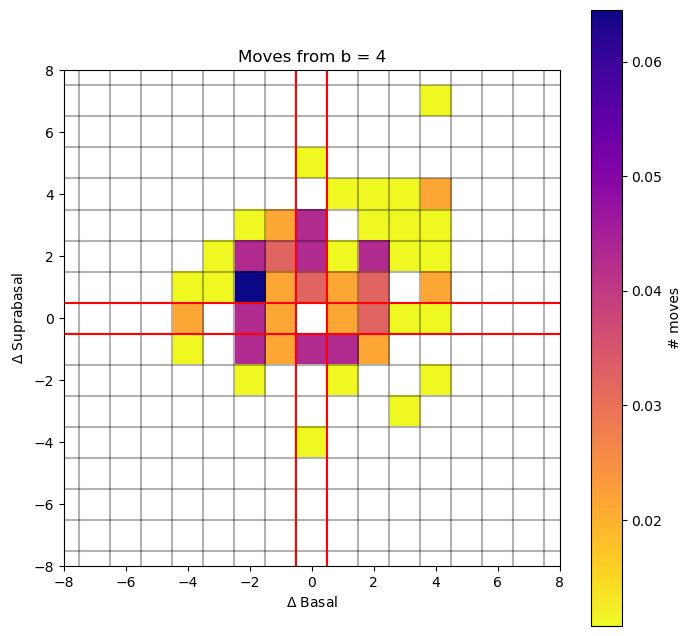

In [7]:

def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, tstart = 0, plot = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'Moves from b = ' + str(init_bas)
    elif init_bas is None and init_sup is not None:
        tit = 'Moves from b = ' + str(init_sup)
    elif init_bas is not None and init_sup is not None:
        tit = 'Moves from (b,s) = (' + str(init_bas) + ',' + str(init_sup) + ')'
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 50] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                print(mb,ms, allmoves[:,mb,ms])


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        plt.figure(figsize=(8,8))
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], origin='lower', cmap = 'plasma_r')
        plt.xlabel(r'$\Delta$ Basal')
        plt.ylabel(r'$\Delta$ Suprabasal')
        if use_log:
            plt.colorbar(label = 'log2(# moves)')
        else:
            plt.colorbar(label = '# moves')
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,2))
        plt.yticks(np.arange(-max_move,max_move+1,2))
        plt.title(tit)
        #plt.axis('square')
        plt.show()
    
    return allmoves
    
allmoves = plot_moves(livesize, init_bas = 4, init_sup = None, normalise=True, max_move = 8, plot = True)

/tmp/ipykernel_217409/3343903776.py:28: RuntimeWarning: invalid value encountered in divide
  frac_even_move[i-1,:] = (even_change - odd_change)/(even_change + odd_change)


Text(0.5, 1.0, 'Bias of moves to even basal #')

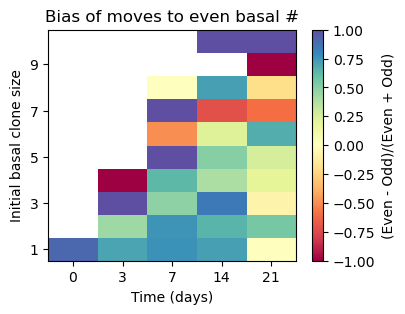

In [8]:
def even_from_state(livesize, init_bas = 1, init_sup = None, max_move = 10, tstart = 0, N = 10):
    full_livesize = np.zeros((livesize.shape[0], livesize.shape[1] + 1, 2), dtype = 'int32')
    full_livesize[:,0,0] = 1
    full_livesize[:,1:,:] = livesize.copy()

    moves = full_livesize[:,tstart+1:,0:3] - full_livesize[:,tstart:-1,0:3] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]

    N = 10
    frac_even_move = np.zeros((N,ntimes))

    for i in range(1,N+1):
        init_bas = i
        moves[np.abs(moves) > 50] = -max_move
        changing = np.sum(np.abs(moves),2) > 0
        if init_bas is None and init_sup is None:
            mask = 1
        elif init_bas is not None and init_sup is None:
            mask = full_livesize[:,tstart:-1,0] == init_bas
        elif init_bas is None and init_sup is not None:
            mask = full_livesize[:,tstart:-1,1] == init_sup
        elif init_bas is not None and init_sup is not None:
            mask = (full_livesize[:,tstart:-1,0] == init_bas) & (full_livesize[:,tstart:-1,1] == init_sup)
            
        even_change = np.sum(((moves[:,:,0] % 2) == 0)*changing*mask,0)
        odd_change  = np.sum(((moves[:,:,0] % 2) == 1)*changing*mask,0)

        frac_even_move[i-1,:] = (even_change - odd_change)/(even_change + odd_change)
        
    return frac_even_move


frac_even_move = even_from_state(livesize, init_bas = 1, init_sup = None, N = 10)
ntimes = np.shape(frac_even_move)[1]
N = np.shape(frac_even_move)[0]
tc = np.array([0] + times)

plt.figure()
plt.imshow(frac_even_move*(-1)**(np.arange(1,N+1)[:,None] % 2), aspect = 'auto', cmap = 'Spectral', extent = [0,ntimes,0.5,N+0.5], origin='lower')
plt.xticks(np.arange(ntimes) + 0.5, labels=tc[:-1])
plt.yticks(np.arange(1,N,2))
plt.colorbar(label = '(Even - Odd)/(Even + Odd)')
plt.xlabel('Time (days)')
plt.ylabel('Initial basal clone size')
plt.title('Bias of moves to even basal #')

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_M18_Lgr6Cre_V1.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_M8_Lgr6Cre_V1.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_F11b_Lgr6Cre_V5.pkl
Repairing basal CS mistakes for [35]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Repairing basal CS mistakes for [35]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Saved to: data_Lgr6_F10b_Lgr6Cre_V5.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_F13_Lgr6Cre_V4.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_M29_Lgr6Cre_V1.pkl


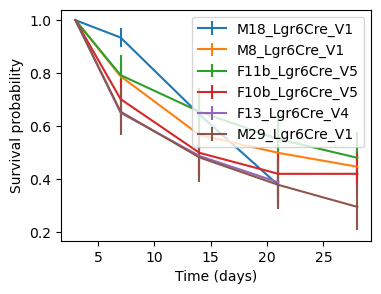

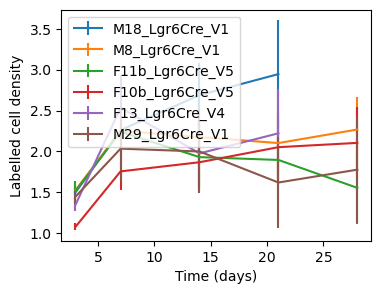

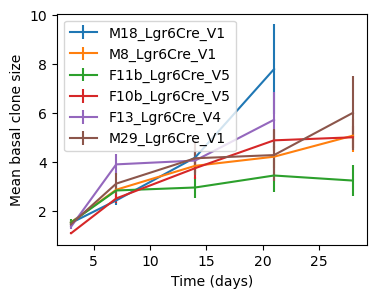

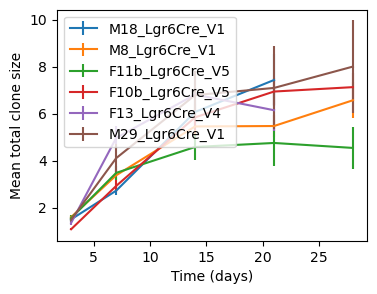

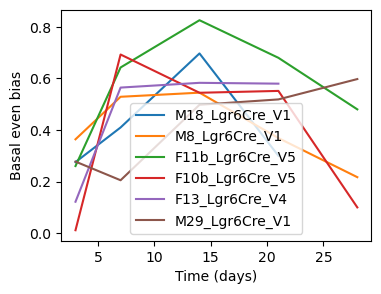

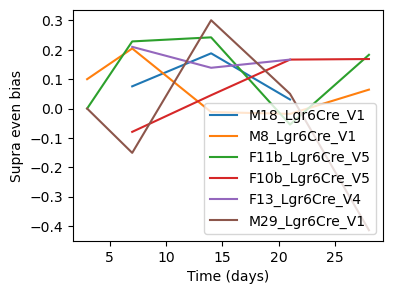

In [9]:
#Mouse-by-mouse data

for mid in mice:        
    sub_timelapse = full_timelapse[full_timelapse['mice_ID'] == mid]
    livesize = np.zeros((len(sub_timelapse), len(times), 2), dtype = 'int32')
    livesize[:,:,0] = np.array(sub_timelapse[bas_names].values, dtype = 'int32')
    livesize[:,:,1] = np.array(sub_timelapse[sup_names].values, dtype = 'int32')
    
    inctimes = np.max(np.min(livesize,2),0) >= 0
    livesize = livesize[:, inctimes, :]
    lcs = clones.lanalysis(livesize, tvals = np.array(times)[inctimes], containsBasal = True)


    data = {}
    data['ctrBasalsize'] = lcs.av_bas_cs
    data['ctrSuprasize'] = lcs.av_sup_cs
    data['ctrTotalsize'] = lcs.av_tot_cs
    data['ctrBasalEvenbias'] = lcs.ev_bas_cs
    data['ctrSupraEvenbias'] = lcs.ev_sup_cs
    data['ctrTotalEvenbias'] = lcs.ev_tot_cs

    data['livesize'] = livesize
    data['ctrjointpdf'] = lcs.joint_pdf

    data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
    data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
    data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
    data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
    data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
    data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

    data['all_moves'] = lcs.allmoves()
    data['all_moves_bas'] = lcs.allmoves_bas()

    cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
    cpdf[:lcs.bas_pdf().shape[0],0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
    cpdf[:lcs.bas_pdf().shape[0],1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
    cpdf[:lcs.bas_pdf().shape[0],2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

    data['ctrpdf'] = cpdf

    data['surprob'] = lcs.pers
    data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


    lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
    data['lcd']     = lcs.lcd
    data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
    data['nallc'] = lcs.non_missing
    data['ctrNsamples'] = lcs.nsur

    data['ctrTimeClonesize'] = lcs.tvals

    save_object(data,    'data_Lgr6_' + mid + '.pkl')
    print('Saved to: ' + 'data_Lgr6_' + mid + '.pkl')


ct = 'Lgr6'
plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']
    lcd        = exp_data['lcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']


    plt.errorbar(te, surprob, np.sqrt(surprob*(1-surprob)/N), label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')   
plt.legend()
plt.show()


plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    lcd_se     = exp_data['SDlcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']
    data['ctrNsamples'] = lcs.nsur 

    plt.errorbar(te, lcd, lcd_se, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean basal clone size')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrTotalsize']
    se_bas_ctr = exp_data['ctrSDTotalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean total clone size')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_bas_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Basal even bias')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data_' + ct + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_sup_ctr = exp_data['ctrSupraEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_sup_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Supra even bias')   
plt.legend()
plt.show()        
    

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_Lgr6_M.pkl
Repairing basal CS mistakes for [66]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Repairing basal CS mistakes for [66]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Saved to: data_Lgr6_F.pkl


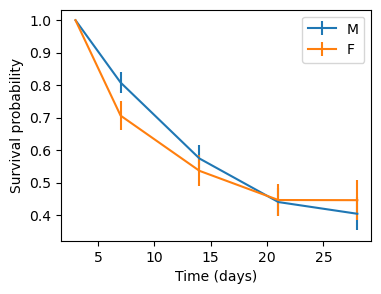

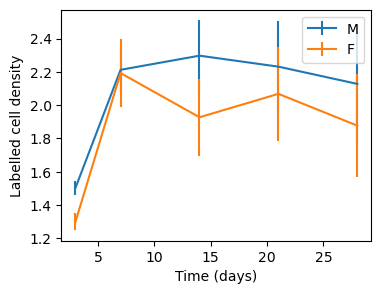

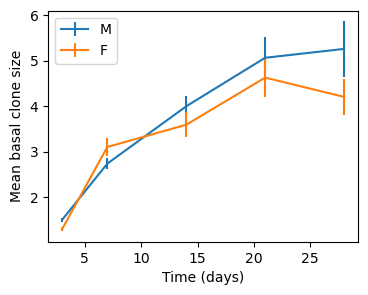

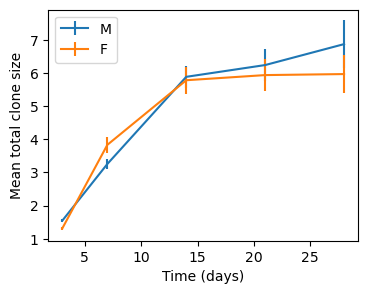

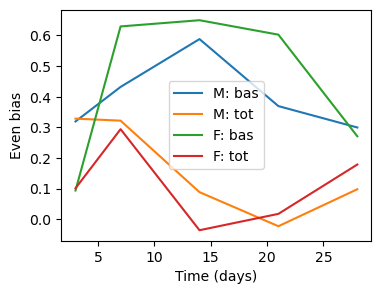

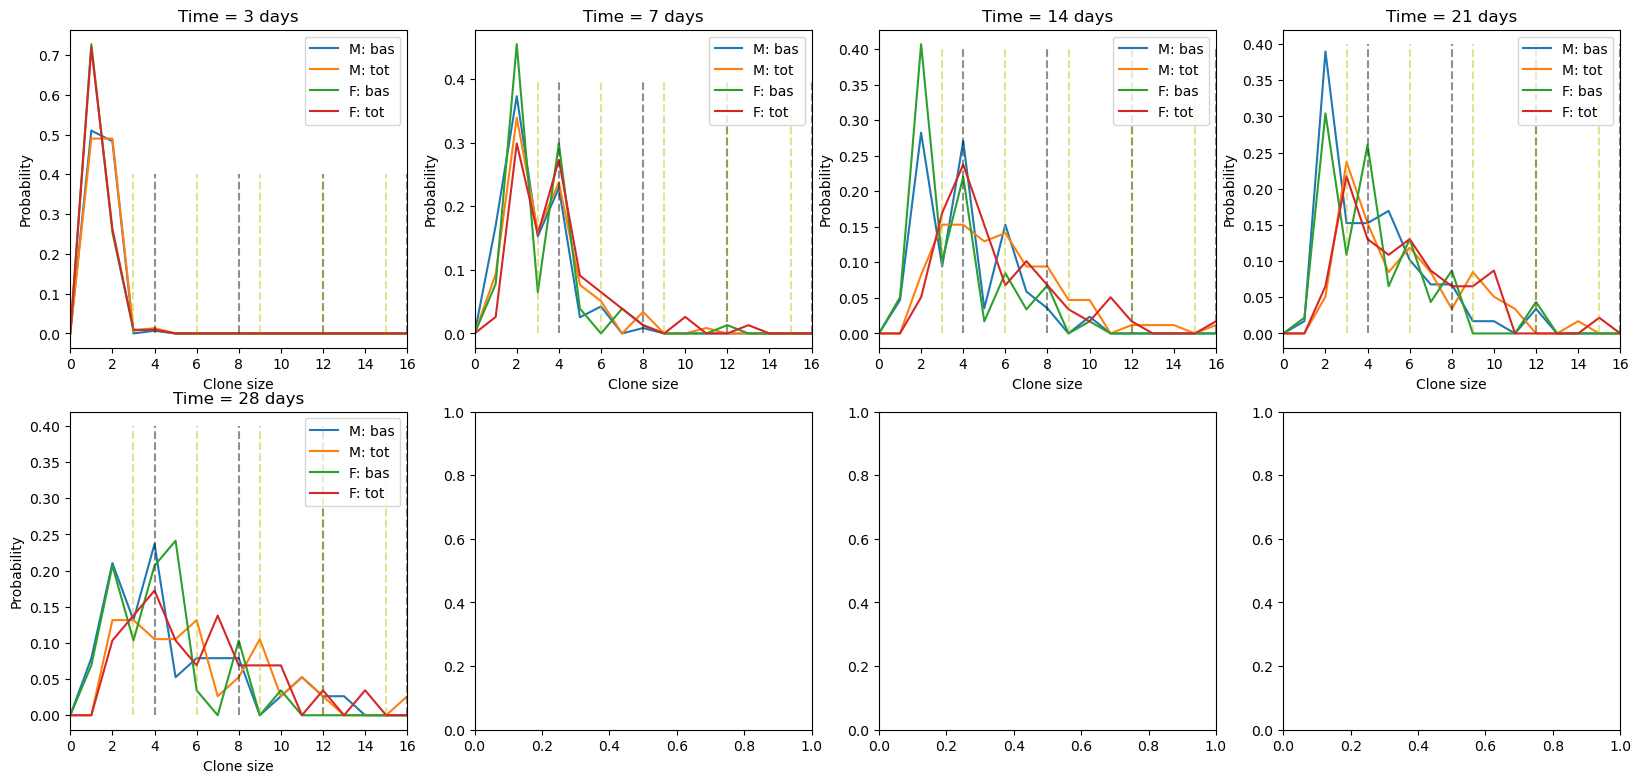

In [10]:
#Data by sex
sexes = ['M', 'F']

for sex in sexes:        
    sub_timelapse = full_timelapse[full_timelapse['sex'] == sex]
    livesize = np.zeros((len(sub_timelapse), len(times), 2), dtype = 'int32')
    livesize[:,:,0] = np.array(sub_timelapse[bas_names].values, dtype = 'int32')
    livesize[:,:,1] = np.array(sub_timelapse[sup_names].values, dtype = 'int32')
    
    inctimes = np.max(np.min(livesize,2),0) >= 0
    livesize = livesize[:, inctimes, :]
    lcs = clones.lanalysis(livesize, tvals = np.array(times)[inctimes], containsBasal = True)

    data = {}
    data['ctrBasalsize'] = lcs.av_bas_cs
    data['ctrSuprasize'] = lcs.av_sup_cs
    data['ctrTotalsize'] = lcs.av_tot_cs
    data['ctrBasalEvenbias'] = lcs.ev_bas_cs
    data['ctrSupraEvenbias'] = lcs.ev_sup_cs
    data['ctrTotalEvenbias'] = lcs.ev_tot_cs

    data['livesize'] = livesize
    data['ctrjointpdf'] = lcs.joint_pdf

    data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
    data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
    data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
    data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
    data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
    data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

    data['all_moves'] = lcs.allmoves()
    data['all_moves_bas'] = lcs.allmoves_bas()


    cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
    cpdf[:lcs.bas_pdf().shape[0],0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
    cpdf[:lcs.bas_pdf().shape[0],1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
    cpdf[:lcs.bas_pdf().shape[0],2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

    data['ctrpdf'] = cpdf

    data['surprob'] = lcs.pers
    data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


    lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
    data['lcd']     = lcs.lcd
    data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
    data['nallc'] = lcs.non_missing
    data['ctrNsamples'] = lcs.nsur

    data['ctrTimeClonesize'] = lcs.tvals

    save_object(data,    'data_Lgr6_' + sex + '.pkl')
    print('Saved to: ' + 'data_Lgr6_' + sex + '.pkl')

plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']
    lcd        = exp_data['lcd']
    N = exp_data['nallc']  
    tvals = exp_data['ctrTimeClonesize'] 

    plt.errorbar(tvals, surprob, np.sqrt(surprob*(1-surprob)/N), label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')   
plt.legend()
plt.show()


plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    lcd_se     = exp_data['SDlcd']
    N = exp_data['nallc']  
    tvals = exp_data['ctrTimeClonesize']      

    plt.errorbar(tvals, lcd, lcd_se, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')   
plt.legend()
plt.show()

plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']          

    plt.errorbar(tvals, av_bas_ctr, se_bas_ctr, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Mean basal clone size')   
plt.legend()
plt.show()

plt.figure()
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    av_tot_ctr = exp_data['ctrTotalsize']
    se_tot_ctr = exp_data['ctrSDTotalsize']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']      

    plt.errorbar(tvals, av_tot_ctr, se_tot_ctr, label = sex)
plt.xlabel('Time (days)')
plt.ylabel('Mean total clone size')   
plt.legend()
plt.show()

plt.figure()

for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')

    surprob    = exp_data['surprob']
    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias']    
    lcd        = exp_data['lcd']
    tvals = exp_data['ctrTimeClonesize']          

    plt.plot(np.array(tvals), ev_bas_ctr, label = sex + ': bas')
    plt.plot(np.array(tvals), ev_tot_ctr, label = sex + ': tot')  
plt.legend()  
plt.xlabel('Time (days)')
plt.ylabel('Even bias')
plt.legend()
plt.show()


fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
for sex in sexes:
    exp_data = load_object('data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']

    for t in range(cpdf.shape[0]):
        xx = t // 4
        yy = t % 4
        axs[xx,yy].plot(cpdf[t,np.array([0,2]),:].T)
        axs[xx,yy].legend(['M: bas', 'M: tot', 'F: bas', 'F: tot'])
        axs[xx,yy].set_xlabel('Clone size')
        axs[xx,yy].set_ylabel('Probability')
        axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
        axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
        axs[xx,yy].set_xlim([0, 16])
        axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
plt.show()      
    

In [11]:
lcs.xfrac()

array([0.        , 0.48275862, 0.29310345, 0.0862069 , 0.06896552,
       0.05172414, 0.01724138, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        ])